Machine learning projects


In [106]:
#import the libaries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

In [107]:
# load the data
df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [108]:
#create the data folder inside the ml_project.
os.makedirs('./data', exist_ok=True)

In [109]:
#save the data as csv file inside data.
df.to_csv('./data/tips.csv', index=False)

In [110]:
# Differentate the features and target variable
x = df.drop('tip', axis=1)
y = df['tip']

In [111]:
x.head()

,total_bill,sex,smoker,day,time,size
0,16.99,Female,No,Sun,Dinner,2
1,10.34,Male,No,Sun,Dinner,3
2,21.01,Male,No,Sun,Dinner,3
3,23.68,Male,No,Sun,Dinner,2
4,24.59,Female,No,Sun,Dinner,4


In [112]:
y.head()

0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

In [113]:
#encode the categorical data.
x = pd.get_dummies(x, columns=['sex', 'smoker', 'day', 'time'], dtype=int)


In [114]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [115]:
#Splitting the data into training and testing data.
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [116]:
x_train.shape

(195, 12)

In [117]:
#train the model using linear regression
from sklearn.linear_model import LinearRegression
model_lin = LinearRegression()
model_lin.fit(x_train, y_train)

# save the trained model
os.makedirs('./model', exist_ok=True)
joblib.dump(model_lin, './model/tip_model.pkl')
print('Model saved to ./model/tip_model.pkl')


Model saved to ./model/tip_model.pkl


In [118]:
#predict the model using linear regression
y_pred_lin = model_lin.predict(x_test)  
pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_lin}).head()

,Actual,Predicted
24,3.18,2.914366
6,2.00,2.002926
153,2.00,3.964256
211,5.16,3.763808
198,2.00,2.148363


In [119]:
#Train the model using Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
model_rf = RandomForestRegressor()
model_rf.fit(x_train, y_train)



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [120]:
#predict the model using Random Forest Regressor
y_pred_rf = model_rf.predict(x_test)
pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_rf}).head()

,Actual,Predicted
24,3.18,2.8114
6,2.00,2.2114
153,2.00,3.7758
211,5.16,3.3048
198,2.00,1.9290


In [121]:
#comaprision the model using r2 score
from sklearn.metrics import accuracy_score, mean_squared_error, mean_absolute_error,r2_score
print("Linear Regression R2 Score:", r2_score(y_test, y_pred_lin))
print("Random Forest Regressor R2 Score:", r2_score(y_test, y_pred_rf))
print("Linear Regression Mean Squared Error:", mean_squared_error(y_test, y_pred_lin))
print("Random Forest Regressor Mean Squared Error:", mean_squared_error(y_test, y_pred_rf))
print("Linear Regression Mean Absolute Error:", mean_absolute_error(y_test, y_pred_lin))
print("Random Forest Regressor Mean Absolute Error:", mean_absolute_error(y_test, y_pred_rf))


Linear Regression R2 Score: 0.43730181943482527
Random Forest Regressor R2 Score: 0.2880400981253639
Linear Regression Mean Squared Error: 0.7033566017436101
Random Forest Regressor Mean Squared Error: 0.8899294763265317
Linear Regression Mean Absolute Error: 0.6671331480264892
Random Forest Regressor Mean Absolute Error: 0.7571755102040817


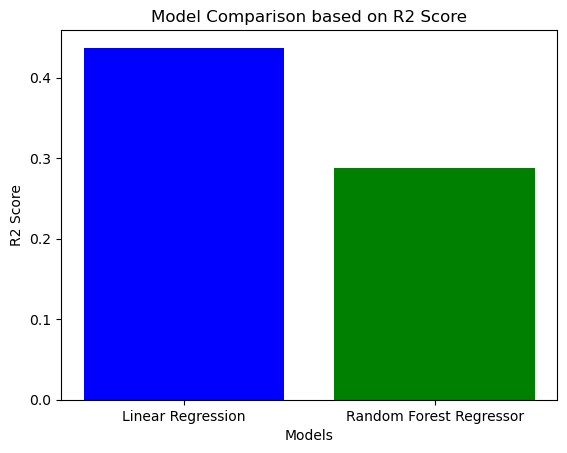

In [122]:
#Comaprision the model on the basis of R2_score in bar graph.
models = ['Linear Regression', 'Random Forest Regressor']
r2_scores = [r2_score(y_test, y_pred_lin), r2_score(y_test, y_pred_rf)]
plt.bar(models, r2_scores,color=['blue', 'green'])
plt.title('Model Comparison based on R2 Score')
plt.xlabel('Models')
plt.ylabel('R2 Score')
plt.show()

We will use Linear Regression model for our project as it has better R2 score and less error rate than Random Forest Regressor.

In [123]:
# Save the model with linear regression
# create a folder named model.
if not os.path.exists('./models'):
    os.makedirs('./models')
joblib.dump(model_lin, './models/linear_regression_model.pkl')

['./models/linear_regression_model.pkl']